# Analytics and Systems of Big Data – Endsem Lab Hackathon
## Dataset: Novo Campeonato Brasileiro

In [172]:
#Setup and Dataset Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter
import math
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score
from sklearn.cluster import KMeans


In [173]:
df = pd.read_csv('novo_campeonato_brasileiro.csv')
print(f'There are {df.shape[0]} rows and {df.shape[1]} columns')
print("First 5 records:")
print(df.head())

print("\nColumns in the dataset:")
print(df.columns.tolist())
print("\nData Types:")
print(df.dtypes)

There are 6886 rows and 13 columns
First 5 records:
             ID        Data   Ano  Rodada Equipe_mandante Equipe_visitante  \
0  2003.01.0001  29/03/2003  2003       1         Guarani            Vasco   
1  2003.01.0002  29/03/2003  2003       1    Athletico-PR           Grêmio   
2  2003.01.0003  30/03/2003  2003       1        Flamengo         Coritiba   
3  2003.01.0004  30/03/2003  2003       1           Goiás         Paysandu   
4  2003.01.0005  30/03/2003  2003       1   Internacional      Ponte Preta   

   Gols_mandante  Gols_visitante Mandante_UF Visitante_UF  Vencedor  \
0              4               2          SP           RJ  Mandante   
1              2               0          PR           RS  Mandante   
2              1               1          RJ           PR    Empate   
3              2               2          GO           PA    Empate   
4              1               1          RS           SP    Empate   

              Arena  OBS  
0    Brinco de Ouro  NaN 

In [174]:
#Dataset Inspection
print("Missing Values:")
display(df.isnull().sum())

print("\nMissing Value Percentage:")
display((df.isnull().sum() / len(df)) * 100)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDuplicate Match IDs:", df["ID"].duplicated().sum())

categorical_cols = df.select_dtypes(include="object").columns

numeric_cols = df.select_dtypes(include=np.number).columns


print("\nOBS Value Counts:")
display(df["OBS"].value_counts(dropna=False))

#Check Negative goals
print("\nNegative Home Goals:", (df["Gols_mandante"] < 0).sum())
print("Negative Away Goals:", (df["Gols_visitante"] < 0).sum())

goal_cols = ['Gols_mandante', 'Gols_visitante'] #Goals outliers
for col in goal_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"\nQ1: {Q1}, Q3: {Q3}, IQR: {IQR}, Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")
    print(f"\nOutliers in {col}:")
    display(outliers[["Data", "Equipe_mandante", "Equipe_visitante",
                      "Gols_mandante", "Gols_visitante", "Vencedor"]])


Missing Values:


ID                     0
Data                   0
Ano                    0
Rodada                 0
Equipe_mandante        0
Equipe_visitante       0
Gols_mandante          0
Gols_visitante         0
Mandante_UF            0
Visitante_UF           0
Vencedor               0
Arena                  0
OBS                 6875
dtype: int64


Missing Value Percentage:


ID                   0.000000
Data                 0.000000
Ano                  0.000000
Rodada               0.000000
Equipe_mandante      0.000000
Equipe_visitante     0.000000
Gols_mandante        0.000000
Gols_visitante       0.000000
Mandante_UF          0.000000
Visitante_UF         0.000000
Vencedor             0.000000
Arena                0.000000
OBS                 99.840256
dtype: float64


Duplicate Rows: 0

Duplicate Match IDs: 0

OBS Value Counts:


OBS
NaN          6875
REMARCADO      11
Name: count, dtype: int64


Negative Home Goals: 0
Negative Away Goals: 0

Q1: 1.0, Q3: 2.0, IQR: 1.0, Lower Bound: -0.5, Upper Bound: 3.5

Outliers in Gols_mandante:


,Data,Equipe_mandante,Equipe_visitante,Gols_mandante,Gols_visitante,Vencedor
0,29/03/2003,Guarani,Vasco,4,2,Mandante
23,06/04/2003,Vasco,Goiás,6,4,Mandante
28,12/04/2003,Corinthians,Paysandu,6,1,Mandante
36,13/04/2003,Flamengo,Fluminense,4,1,Mandante
56,20/04/2003,Ponte Preta,Paysandu,4,4,Empate
...,...,...,...,...,...,...
6840,24/11/2019,Goiás,Bahia,4,3,Mandante
6850,27/11/2019,Flamengo,Ceará,4,1,Mandante
6873,05/12/2019,Palmeiras,Goiás,5,1,Mandante
6875,05/12/2019,Flamengo,Avaí,6,1,Mandante



Q1: 0.0, Q3: 2.0, IQR: 2.0, Lower Bound: -3.0, Upper Bound: 5.0

Outliers in Gols_visitante:


,Data,Equipe_mandante,Equipe_visitante,Gols_mandante,Gols_visitante,Vencedor
450,22/10/2003,Bahia,Santos,4,7,Visitante
547,14/12/2003,Bahia,Cruzeiro,0,7,Visitante
1353,07/09/2005,Cruzeiro,Fluminense,2,6,Visitante
1446,16/10/2005,Flamengo,São Paulo,1,6,Visitante
1542,20/11/2005,Ponte Preta,Palmeiras,2,6,Visitante
1946,12/05/2007,Figueirense,Athletico-PR,3,6,Visitante
2464,17/07/2008,Figueirense,Grêmio,1,7,Visitante
5794,08/06/2017,Chapecoense,Grêmio,3,6,Visitante


In [175]:
#Data Cleaning and Preprocessing
df_clean = df.copy()

df_clean.drop(columns=["OBS"], inplace=True) #High Nullity Column

#The Outlier values represent valid match results and hence will not be removed. There are no negative values in the goals columns. Hence, no further cleaning is required.
print("Dataset after cleaning")
print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

Dataset after cleaning
Original Shape: (6886, 13)
Cleaned Shape: (6886, 12)


In [176]:
#Data Selection
attribute_groups = {
    'Descriptive Analytics': [
        "Data", "Ano", "Rodada", "Equipe_mandante",
        "Equipe_visitante", "Gols_mandante", "Gols_visitante",
        "Mandante_UF", "Visitante_UF", "Vencedor", "Arena"
    ],
    'ARM': [
        "Ano", "Rodada", "Mandante_UF", "Visitante_UF",
        "Gols_mandante", "Gols_visitante", "Vencedor"
    ],
    'Naive_Bayes': [
        "Ano", "Rodada", "Mandante_UF", "Visitante_UF",
        "Gols_mandante", "Gols_visitante", "Vencedor"
    ],
    'Diana':[
        "Ano", "Rodada", "Mandante_UF", "Visitante_UF",
        "Gols_mandante", "Gols_visitante", "Vencedor"
    ]
}

for task, attributes in attribute_groups.items():
    print(f"\n{task}")
    print(f"Selected Attributes: {attributes}")


Descriptive Analytics
Selected Attributes: ['Data', 'Ano', 'Rodada', 'Equipe_mandante', 'Equipe_visitante', 'Gols_mandante', 'Gols_visitante', 'Mandante_UF', 'Visitante_UF', 'Vencedor', 'Arena']

ARM
Selected Attributes: ['Ano', 'Rodada', 'Mandante_UF', 'Visitante_UF', 'Gols_mandante', 'Gols_visitante', 'Vencedor']

Naive_Bayes
Selected Attributes: ['Ano', 'Rodada', 'Mandante_UF', 'Visitante_UF', 'Gols_mandante', 'Gols_visitante', 'Vencedor']

Diana
Selected Attributes: ['Ano', 'Rodada', 'Mandante_UF', 'Visitante_UF', 'Gols_mandante', 'Gols_visitante', 'Vencedor']


In [177]:
#Data Transformation

#Converting Date column to datetime format
df_clean["Data"] = pd.to_datetime(df_clean["Data"], format="%d/%m/%Y")

#Extract month and day
df_clean["Month"] = df_clean["Data"].dt.month
df_clean["Day"] = df_clean["Data"].dt.day

#Deriving new features - Total Goals and Goal Difference(-ve = Away team wins)
df_clean["Total_Goals"] = df_clean["Gols_mandante"] + df_clean["Gols_visitante"]
df_clean["Goal_Difference"] = (df_clean["Gols_mandante"] - df_clean["Gols_visitante"])

# Derive match outcome using Goal_Difference
df_clean["Outcome"] = "Draw"
df_clean.loc[df_clean["Goal_Difference"] > 0, "Outcome"] = "Home Win"
df_clean.loc[df_clean["Goal_Difference"] < 0, "Outcome"] = "Away Win"

print("\nData Types after Transformation:")
print(df_clean.dtypes)

print("\nFirst 5 records after Transformation:")
print(df_clean.head())


Data Types after Transformation:
ID                          object
Data                datetime64[ns]
Ano                          int64
Rodada                       int64
Equipe_mandante             object
Equipe_visitante            object
Gols_mandante                int64
Gols_visitante               int64
Mandante_UF                 object
Visitante_UF                object
Vencedor                    object
Arena                       object
Month                        int32
Day                          int32
Total_Goals                  int64
Goal_Difference              int64
Outcome                     object
dtype: object

First 5 records after Transformation:
             ID       Data   Ano  Rodada Equipe_mandante Equipe_visitante  \
0  2003.01.0001 2003-03-29  2003       1         Guarani            Vasco   
1  2003.01.0002 2003-03-29  2003       1    Athletico-PR           Grêmio   
2  2003.01.0003 2003-03-30  2003       1        Flamengo         Coritiba   
3  2003.01

### Data Visualization

In [178]:
#Data Visualization
df_plot = df_clean.copy()
outcome_order = ["Home Win", "Draw", "Away Win"]
max_round_per_year = df_plot.groupby("Ano")["Rodada"].transform("max")

df_plot["Scoreline"] = (
    df_plot["Gols_mandante"].astype(str)
    + " - "
    + df_plot["Gols_visitante"].astype(str)
)
df_plot["Round_Progress"] = df_plot["Rodada"] / max_round_per_year

df_plot["Round_Phase"] = np.select(
    [
        df_plot["Round_Progress"] <= 1/3,
        df_plot["Round_Progress"] <= 2/3
    ],
    ["Early", "Middle"],
    default="Late"
)

phase_order = ["Early", "Middle", "Late"]

print("Dataset prepared for visualizations:", df_plot.shape)


Dataset prepared for visualizations: (6886, 20)


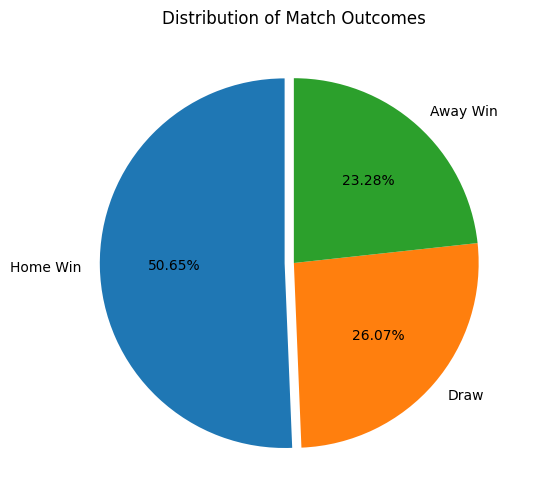

In [179]:
# 1. PIE CHART

outcome_counts = df_plot["Outcome"].value_counts().sort_index(ascending=False)

plt.figure(figsize=(8, 6))

plt.pie(
    outcome_counts,
    labels=outcome_order,
    autopct="%1.2f%%",
    startangle=90,
    explode=(0.05, 0, 0)
)

plt.title("Distribution of Match Outcomes")
plt.show()


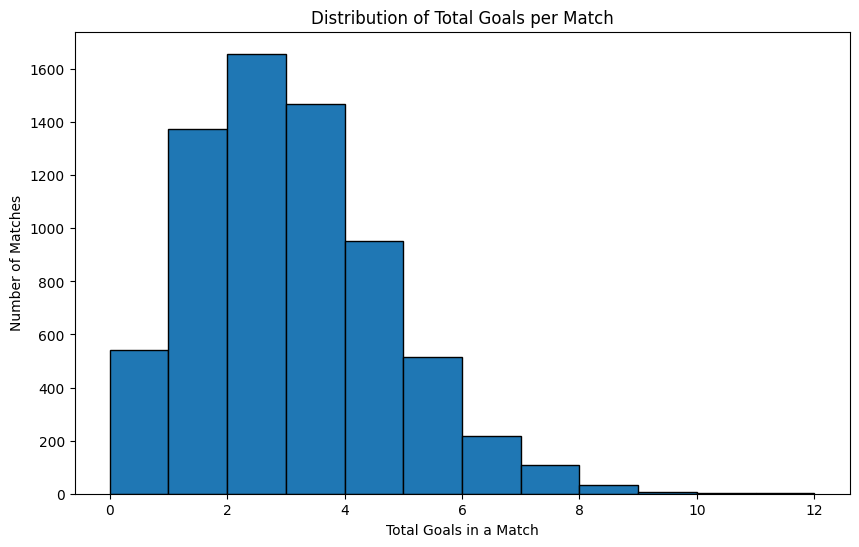

In [180]:
# 2. HISTOGRAM

plt.figure(figsize=(10, 6))

plt.hist(
    df_plot["Total_Goals"],
    bins=np.arange(
        df_plot["Total_Goals"].min(),
        df_plot["Total_Goals"].max() + 2
    ),
    edgecolor="black"
)

plt.xlabel("Total Goals in a Match")
plt.ylabel("Number of Matches")
plt.title("Distribution of Total Goals per Match")

plt.show()

C:\Users\shash\AppData\Local\Temp\ipykernel_5680\2014486940.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


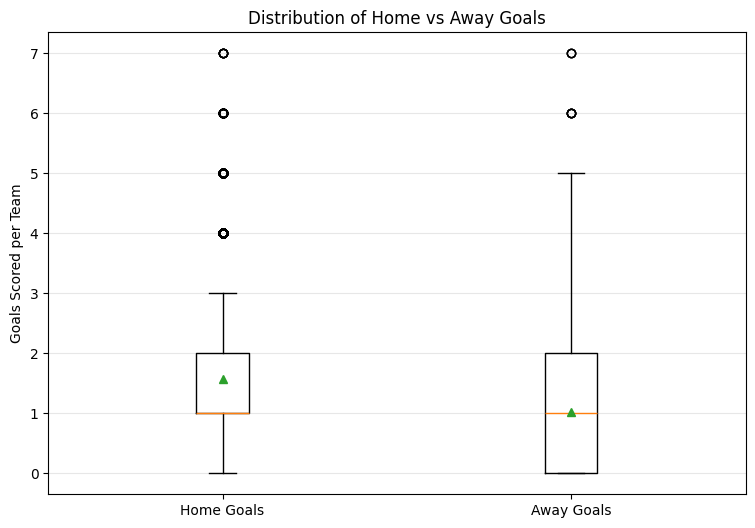

In [181]:
# 3. BOX AND WHISKER PLOT 

plt.figure(figsize=(9, 6))

plt.boxplot(
    [df_plot["Gols_mandante"], df_plot["Gols_visitante"]],
    labels=["Home Goals", "Away Goals"],
    showmeans=True
)

plt.ylabel("Goals Scored per Team")
plt.title("Distribution of Home vs Away Goals")

plt.grid(axis="y", alpha=0.3)
plt.show()

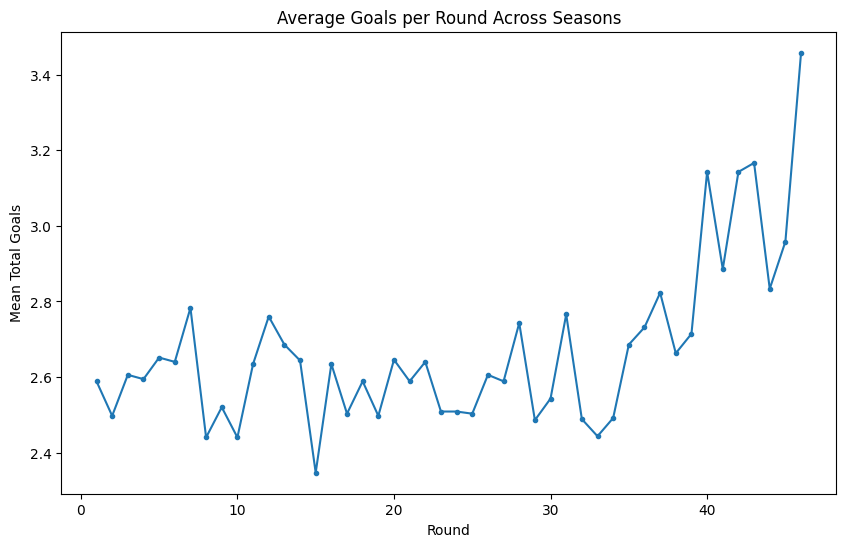

In [182]:
# 4. LINE CHART
round_goals = df_plot.groupby("Rodada")["Total_Goals"].mean().sort_index()

plt.figure(figsize=(10, 6))

plt.plot(
    round_goals.index,
    round_goals.values,
    linestyle="-",
    marker = '.'
)

plt.xlabel("Round")
plt.ylabel("Mean Total Goals")
plt.title("Average Goals per Round Across Seasons")

plt.show()


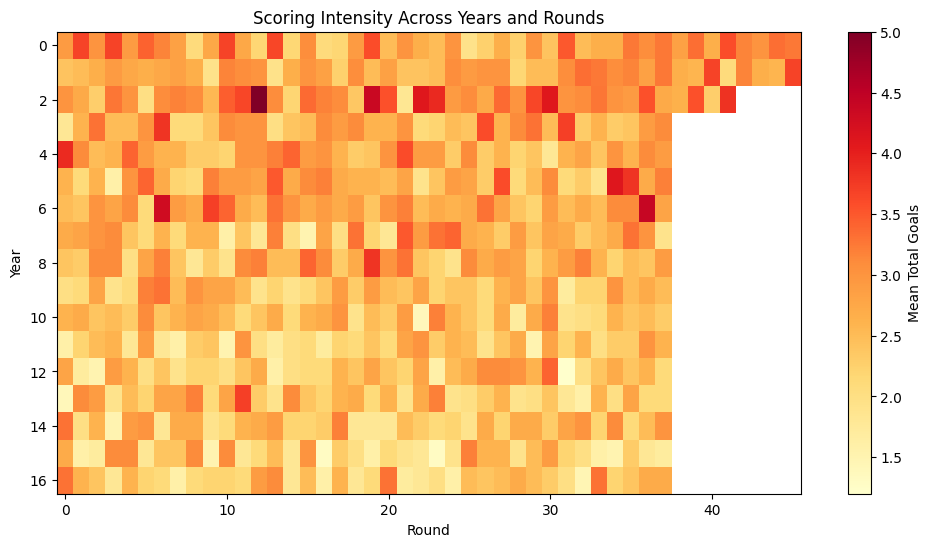

In [183]:
# 5. HEATMAP

year_round_goals = df_plot.pivot_table(
    index="Ano",
    columns="Rodada",
    values="Total_Goals",
    aggfunc="mean"
)

plt.figure(figsize=(12, 6))

plt.imshow(
    year_round_goals,
    aspect="auto",
    interpolation="nearest",
    cmap="YlOrRd"
)

plt.colorbar(label="Mean Total Goals")

plt.xlabel("Round")
plt.ylabel("Year")
plt.title("Scoring Intensity Across Years and Rounds")

plt.show()

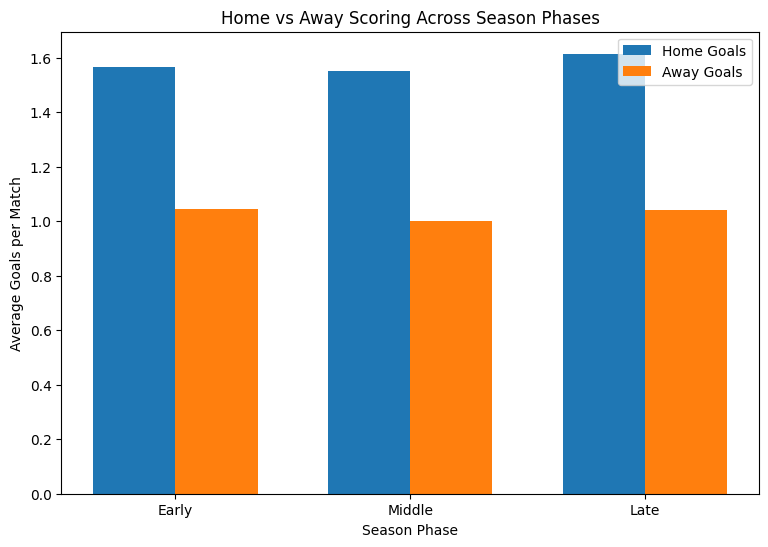

In [184]:
# 6. BAR CHART 

phase_goals = df_plot.groupby("Round_Phase")[
    ["Gols_mandante", "Gols_visitante"]
].mean().reindex(phase_order)

x = np.arange(len(phase_order))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width/2,
    phase_goals["Gols_mandante"],
    width,
    label="Home Goals"
)

plt.bar(
    x + width/2,
    phase_goals["Gols_visitante"],
    width,
    label="Away Goals"
)

plt.xticks(x, phase_order)
plt.xlabel("Season Phase")
plt.ylabel("Average Goals per Match")
plt.title("Home vs Away Scoring Across Season Phases")
plt.legend()

plt.show()



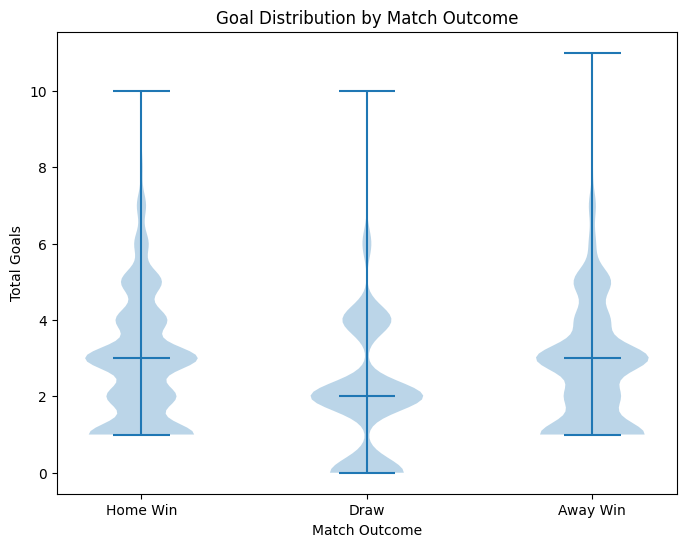

In [185]:
# 7. VIOLIN PLOT 

violin_data = [
    df_plot.loc[df_plot["Outcome"] == outcome, "Total_Goals"].values
    for outcome in outcome_order
]

plt.figure(figsize=(8, 6))

plt.violinplot(
    violin_data,
    showmedians=True,
    showextrema=True
)

plt.xticks(range(1, 4), outcome_order)
plt.xlabel("Match Outcome")
plt.ylabel("Total Goals")
plt.title("Goal Distribution by Match Outcome")

plt.show()



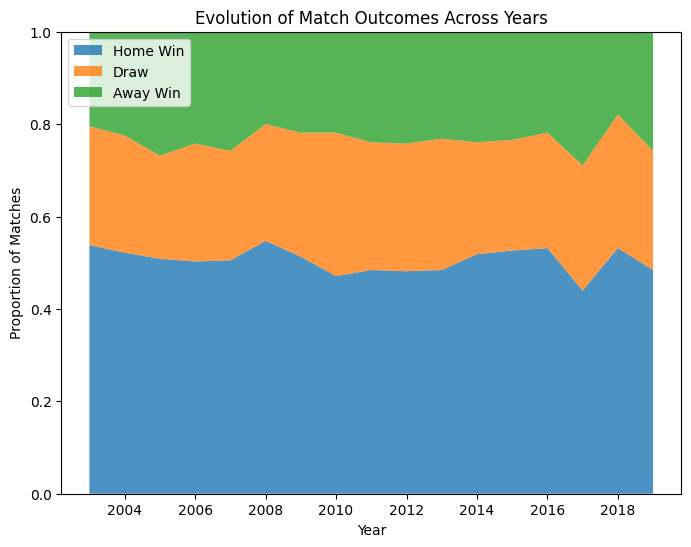

In [186]:
# 8. STACKED AREA CHART 

year_outcomes = pd.crosstab(
    df_plot["Ano"],
    df_plot["Outcome"],
    normalize="index"
).reindex(columns=outcome_order, fill_value=0)

plt.figure(figsize=(8, 6))

plt.stackplot(
    year_outcomes.index,
    year_outcomes["Home Win"],
    year_outcomes["Draw"],
    year_outcomes["Away Win"],
    labels=outcome_order,
    alpha=0.8
)

plt.xlabel("Year")
plt.ylabel("Proportion of Matches")
plt.title("Evolution of Match Outcomes Across Years")
plt.legend(loc="upper left")
plt.ylim(0, 1)

plt.show()


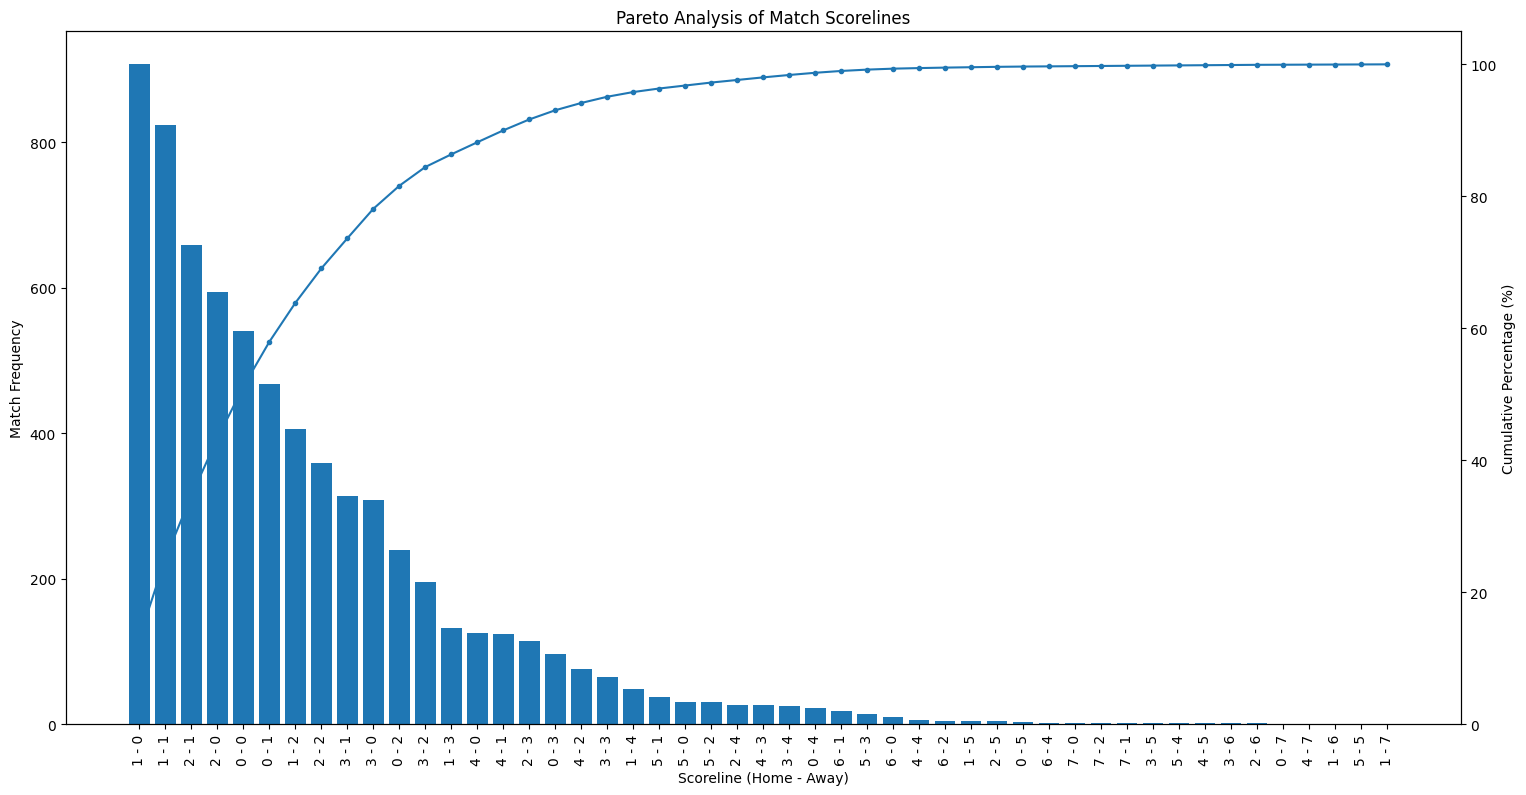

In [187]:
# 9. PARETO CHART

score_counts = df_plot["Scoreline"].value_counts().sort_values(ascending=False)

cumulative_percentage = (
    score_counts.cumsum() / score_counts.sum() * 100
)

fig, ax1 = plt.subplots(figsize=(18, 9))

ax1.bar(
    range(len(score_counts)),
    score_counts.values
)

ax1.set_xlabel("Scoreline (Home - Away)")
ax1.set_ylabel("Match Frequency")
ax1.set_title("Pareto Analysis of Match Scorelines")
ax1.set_xticks(range(len(score_counts)))
ax1.set_xticklabels(score_counts.index, rotation=90)

ax2 = ax1.twinx()

ax2.plot(
    range(len(score_counts)),
    cumulative_percentage.values,
    marker=".",
    linestyle="-"
)

ax2.set_ylabel("Cumulative Percentage (%)")
ax2.set_ylim(0, 105)

plt.show()




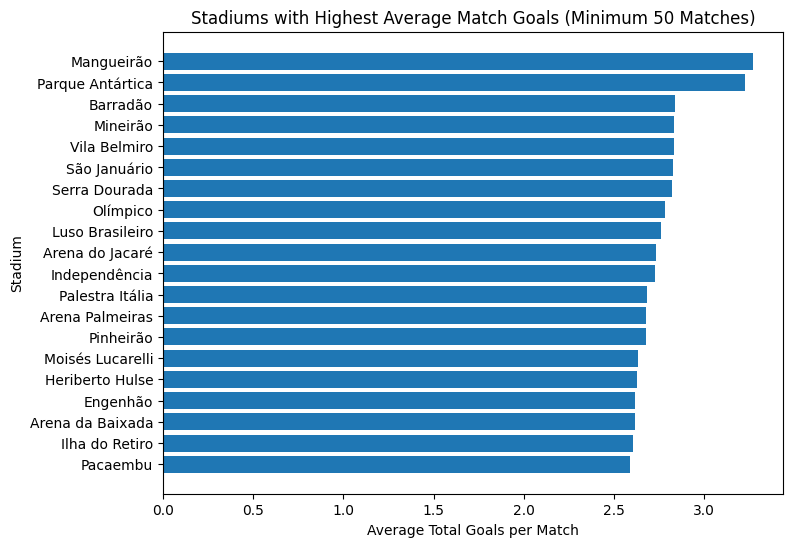

In [188]:
# 10. HORIZONTAL BAR CHART 
stadium_stats = df_plot.groupby("Arena").agg(
    Matches=("Total_Goals", "count"),
    Mean_Goals=("Total_Goals", "mean")
)

# Remove stadiums with fewer than 50 matches
stadium_stats = stadium_stats[stadium_stats["Matches"] >= 50]

# Select 20 stadiums with highest average goals
top_stadiums = stadium_stats.sort_values(
    "Mean_Goals", ascending=False
).head(20)

top_stadiums = top_stadiums.sort_values("Mean_Goals")

plt.figure(figsize=(8, 6))

plt.barh(
    top_stadiums.index,
    top_stadiums["Mean_Goals"]
)

plt.xlabel("Average Total Goals per Match")
plt.ylabel("Stadium")
plt.title("Stadiums with Highest Average Match Goals (Minimum 50 Matches)")

plt.show()


### Predictive Analytics

In [189]:
#Create categorized attributes for transaction-based mining
df_mining = df_clean.copy()

df_mining["Home_Goals_Category"] = pd.cut(
    df_mining["Gols_mandante"], bins=[-1, 0, 1, 2, 3, float("inf")],
    labels=["0", "1", "2", "3", "4+"]
).astype(str)

df_mining["Away_Goals_Category"] = pd.cut(
    df_mining["Gols_visitante"], bins=[-1, 0, 1, 2, 3, float("inf")],
    labels=["0", "1", "2", "3", "4+"]
).astype(str)

df_mining["Total_Goals_Category"] = pd.cut(
    df_mining["Total_Goals"], bins=[-1, 1, 3, 5, 7, float("inf")],
    labels=["0-1", "2-3", "4-5", "6-7", "8+"]
).astype(str)

max_round = df_mining.groupby("Ano")["Rodada"].transform("max")
df_mining["Season_Phase"] = np.select(
    [df_mining["Rodada"] <= max_round / 3, df_mining["Rodada"] <= 2 * max_round / 3],
    ["Early", "Middle"], default="Late"
)

years = sorted(df_mining["Ano"].dropna().unique())
year_groups = np.array_split(years, 3)
period_map = {}
for period, group in zip(["Early Period", "Middle Period", "Late Period"], year_groups):
    for year in group:
        period_map[year] = period

df_mining["Year_Period"] = df_mining["Ano"].map(period_map)

#Match outcomes already derived during transformation
print("Mining dataset shape:", df_mining.shape)
print(df_mining.head())


Mining dataset shape: (6886, 22)
             ID       Data   Ano  Rodada Equipe_mandante Equipe_visitante  \
0  2003.01.0001 2003-03-29  2003       1         Guarani            Vasco   
1  2003.01.0002 2003-03-29  2003       1    Athletico-PR           Grêmio   
2  2003.01.0003 2003-03-30  2003       1        Flamengo         Coritiba   
3  2003.01.0004 2003-03-30  2003       1           Goiás         Paysandu   
4  2003.01.0005 2003-03-30  2003       1   Internacional      Ponte Preta   

   Gols_mandante  Gols_visitante Mandante_UF Visitante_UF  ... Month Day  \
0              4               2          SP           RJ  ...     3  29   
1              2               0          PR           RS  ...     3  29   
2              1               1          RJ           PR  ...     3  30   
3              2               2          GO           PA  ...     3  30   
4              1               1          RS           SP  ...     3  30   

   Total_Goals  Goal_Difference   Outcome  Home

In [190]:
#Create transactions from selected categorical attributes
transaction_columns = [
    "Home_Goals_Category", "Away_Goals_Category", "Total_Goals_Category",
    "Season_Phase", "Year_Period", "Outcome"
]
transactions = [
    frozenset(f"{col}={row[col]}" for col in transaction_columns)
    for _, row in df_mining[transaction_columns].iterrows()
]

#DIC 
def dic_mining(transactions, min_support=0.1, batch_size=500):
    n = len(transactions)
    min_count = math.ceil(min_support * n)
    item_counts = Counter(item for transaction in transactions for item in transaction)
    candidates = {frozenset([item]) for item in item_counts}
    counts = Counter()
    frequent = set()
    discarded = set()

    for start in range(0, n, batch_size):
        batch = transactions[start:start + batch_size]
        active = candidates | frequent
        active_by_size = {}
        for candidate in active:
            active_by_size.setdefault(len(candidate), set()).add(candidate)

        for transaction in batch:
            for size, candidate_sets in active_by_size.items():
                if size > len(transaction):
                    continue
                for combination in combinations(transaction, size):
                    itemset = frozenset(combination)
                    if itemset in candidate_sets:
                        counts[itemset] += 1

        processed = start + len(batch)
        remaining = n - processed
        for candidate in list(candidates):
            if counts[candidate] + remaining < min_count:
                candidates.remove(candidate)
                discarded.add(candidate)
            elif counts[candidate] >= min_count:
                candidates.remove(candidate)
                frequent.add(candidate)

       
        frequent_by_size = {}
        for itemset in frequent:
            frequent_by_size.setdefault(len(itemset), set()).add(itemset)
        if frequent_by_size:
            max_size = max(frequent_by_size)
            previous_level = frequent_by_size.get(max_size, set())
            for left, right in combinations(previous_level, 2):
                candidate = left | right
                if len(candidate) == max_size + 1 and all(
                    frozenset(subset) in frequent for subset in combinations(candidate, max_size)
                ):
                    if candidate not in frequent and candidate not in discarded:
                        candidates.add(candidate)

    verified = Counter()
    all_candidates = candidates | frequent
    for transaction in transactions:
        for candidate in all_candidates:
            if candidate.issubset(transaction):
                verified[candidate] += 1
    return {itemset: count for itemset, count in verified.items() if count >= min_count}

DIC_MIN_SUPPORT = 0.1
DIC_BATCH_SIZE = 500
start_time = time.perf_counter()
dic_frequent = dic_mining(transactions, DIC_MIN_SUPPORT, DIC_BATCH_SIZE)
dic_time = time.perf_counter() - start_time

print("DIC minimum support:", DIC_MIN_SUPPORT)
print("Frequent itemsets found:", len(dic_frequent))
print("Execution time (seconds):", round(dic_time, 3))
print("Top frequent itemsets:")
for itemset, count in sorted(dic_frequent.items(), key=lambda x: x[1], reverse=True)[:20]:
    print(sorted(itemset), "support count:", count, "support:", round(count / len(transactions), 4))


DIC minimum support: 0.1
Frequent itemsets found: 34
Execution time (seconds): 0.053
Top frequent itemsets:
['Outcome=Home Win'] support count: 3488 support: 0.5065
['Total_Goals_Category=2-3'] support count: 3127 support: 0.4541
['Year_Period=Early Period'] support count: 2706 support: 0.393
['Away_Goals_Category=0'] support count: 2518 support: 0.3657
['Away_Goals_Category=1'] support count: 2447 support: 0.3554
['Season_Phase=Late'] support count: 2358 support: 0.3424
['Season_Phase=Middle'] support count: 2334 support: 0.3389
['Home_Goals_Category=1'] support count: 2324 support: 0.3375
['Year_Period=Middle Period'] support count: 2280 support: 0.3311
['Season_Phase=Early'] support count: 2194 support: 0.3186
['Away_Goals_Category=0', 'Outcome=Home Win'] support count: 1978 support: 0.2872
['Total_Goals_Category=0-1'] support count: 1915 support: 0.2781
['Year_Period=Late Period'] support count: 1900 support: 0.2759
['Outcome=Draw'] support count: 1795 support: 0.2607
['Home_Goals_

In [191]:
#Generate association rules from DIC frequent itemsets
def generate_rules(frequent_itemsets, transaction_count, min_confidence=0.60):
    rules = []
    support_counts = frequent_itemsets
    for itemset, count in frequent_itemsets.items():
        if len(itemset) < 2:
            continue
        items = list(itemset)
        for r in range(1, len(items)):
            for antecedent_tuple in combinations(items, r):
                antecedent = frozenset(antecedent_tuple)
                consequent = itemset - antecedent
                antecedent_count = support_counts.get(antecedent)
                if antecedent_count:
                    confidence = count / antecedent_count
                    if confidence >= min_confidence:
                        support = count / transaction_count
                        lift = confidence / (antecedent_count / transaction_count)
                        rules.append((antecedent, consequent, support, confidence, lift))
    return sorted(rules, key=lambda x: (x[4], x[3]), reverse=True)

DIC_MIN_CONFIDENCE = 0.60
dic_rules = generate_rules(dic_frequent, len(transactions), DIC_MIN_CONFIDENCE)
print("Association rules meeting confidence threshold:", len(dic_rules))
for antecedent, consequent, support, confidence, lift in dic_rules[:20]:
    print(f"{sorted(antecedent)} -> {sorted(consequent)} | support={support:.3f}, confidence={confidence:.3f}, lift={lift:.3f}")


Association rules meeting confidence threshold: 9
['Home_Goals_Category=2', 'Total_Goals_Category=2-3'] -> ['Outcome=Home Win'] | support=0.182, confidence=1.000, lift=5.496
['Home_Goals_Category=2', 'Outcome=Home Win'] -> ['Total_Goals_Category=2-3'] | support=0.182, confidence=1.000, lift=5.496
['Outcome=Home Win', 'Total_Goals_Category=2-3'] -> ['Home_Goals_Category=2'] | support=0.182, confidence=0.803, lift=3.541
['Home_Goals_Category=2'] -> ['Outcome=Home Win', 'Total_Goals_Category=2-3'] | support=0.182, confidence=0.712, lift=2.789
['Home_Goals_Category=2'] -> ['Total_Goals_Category=2-3'] | support=0.182, confidence=0.712, lift=2.789
['Home_Goals_Category=2'] -> ['Outcome=Home Win'] | support=0.182, confidence=0.712, lift=2.789
['Total_Goals_Category=0-1'] -> ['Away_Goals_Category=0'] | support=0.210, confidence=0.756, lift=2.717
['Away_Goals_Category=0'] -> ['Outcome=Home Win'] | support=0.287, confidence=0.786, lift=2.148
['Away_Goals_Category=1'] -> ['Total_Goals_Category=2-

In [192]:
#AClose
ACLOSE_MIN_SUPPORT = 0.1
ACLOSE_MIN_CONFIDENCE = 0.60

item_support = Counter(item for transaction in transactions for item in transaction)
min_count_aclose = math.ceil(ACLOSE_MIN_SUPPORT * len(transactions))
aclose_items = [item for item, count in item_support.items() if count >= min_count_aclose]

ACLOSE_MAX_ITEMS = 12
aclose_items = sorted(aclose_items, key=lambda item: item_support[item], reverse=True)[:ACLOSE_MAX_ITEMS]
aclose_transactions = [transaction.intersection(aclose_items) for transaction in transactions]

def aclose_mining(transactions, items, min_support_count):
    frequent = {}
    for size in range(1, len(items) + 1):
        for combination in combinations(items, size):
            itemset = frozenset(combination)
            count = sum(itemset.issubset(transaction) for transaction in transactions)
            if count >= min_support_count:
                frequent[itemset] = count
    closed = {}
    frequent_sets = list(frequent.keys())
    for itemset, count in frequent.items():
        if not any(itemset < superset and frequent[superset] == count for superset in frequent_sets):
            closed[itemset] = count
    return frequent, closed

start_time = time.perf_counter()
aclose_frequent, aclose_closed = aclose_mining(aclose_transactions, aclose_items, min_count_aclose)
aclose_time = time.perf_counter() - start_time

print("Item universe size:", len(aclose_items))
print("Frequent itemsets:", len(aclose_frequent))
print("Closed frequent itemsets:", len(aclose_closed))
print("Execution time (seconds):", round(aclose_time, 3))
for itemset, count in sorted(aclose_closed.items(), key=lambda x: x[1], reverse=True)[:25]:
    print(sorted(itemset), "count:", count, "support:", round(count / len(transactions), 4))


Item universe size: 12
Frequent itemsets: 67
Closed frequent itemsets: 57
Execution time (seconds): 0.819
['Outcome=Home Win'] count: 3488 support: 0.5065
['Total_Goals_Category=2-3'] count: 3127 support: 0.4541
['Year_Period=Early Period'] count: 2706 support: 0.393
['Away_Goals_Category=0'] count: 2518 support: 0.3657
['Away_Goals_Category=1'] count: 2447 support: 0.3554
['Season_Phase=Late'] count: 2358 support: 0.3424
['Season_Phase=Middle'] count: 2334 support: 0.3389
['Home_Goals_Category=1'] count: 2324 support: 0.3375
['Year_Period=Middle Period'] count: 2280 support: 0.3311
['Season_Phase=Early'] count: 2194 support: 0.3186
['Away_Goals_Category=0', 'Outcome=Home Win'] count: 1978 support: 0.2872
['Total_Goals_Category=0-1'] count: 1915 support: 0.2781
['Year_Period=Late Period'] count: 1900 support: 0.2759
['Outcome=Home Win', 'Total_Goals_Category=2-3'] count: 1561 support: 0.2267
['Away_Goals_Category=1', 'Total_Goals_Category=2-3'] count: 1483 support: 0.2154
['Away_Goals_

In [193]:
#Association rules from closed frequent itemsets
def aclose_rules(closed_itemsets, transactions, min_confidence=0.60):
    rules = []
    for itemset, union_count in closed_itemsets.items():
        if len(itemset) < 2:
            continue
        for size in range(1, len(itemset)):
            for antecedent_tuple in combinations(itemset, size):
                antecedent = frozenset(antecedent_tuple)
                consequent = itemset - antecedent
                antecedent_count = sum(antecedent.issubset(t) for t in transactions)
                confidence = union_count / antecedent_count if antecedent_count else 0
                if confidence >= min_confidence:
                    support = union_count / len(transactions)
                    lift = confidence / (antecedent_count / len(transactions)) if antecedent_count else 0
                    rules.append((antecedent, consequent, support, confidence, lift))
    return sorted(rules, key=lambda x: (x[4], x[3]), reverse=True)

aclose_association_rules = aclose_rules(aclose_closed, aclose_transactions, ACLOSE_MIN_CONFIDENCE)
print("Rules generated from closed frequent itemsets:", len(aclose_association_rules))
for antecedent, consequent, support, confidence, lift in aclose_association_rules[:20]:
    print(f"{sorted(antecedent)} -> {sorted(consequent)} | support={support:.3f}, confidence={confidence:.3f}, lift={lift:.3f}")


Rules generated from closed frequent itemsets: 17
['Away_Goals_Category=1', 'Home_Goals_Category=1'] -> ['Total_Goals_Category=2-3'] | support=0.120, confidence=1.000, lift=8.357
['Away_Goals_Category=0', 'Total_Goals_Category=2-3'] -> ['Outcome=Home Win'] | support=0.131, confidence=1.000, lift=7.634
['Outcome=Home Win', 'Total_Goals_Category=0-1'] -> ['Away_Goals_Category=0', 'Home_Goals_Category=1'] | support=0.132, confidence=1.000, lift=7.592
['Home_Goals_Category=1', 'Total_Goals_Category=0-1'] -> ['Away_Goals_Category=0', 'Outcome=Home Win'] | support=0.132, confidence=1.000, lift=7.592
['Home_Goals_Category=1', 'Outcome=Home Win'] -> ['Away_Goals_Category=0', 'Total_Goals_Category=0-1'] | support=0.132, confidence=1.000, lift=7.592
['Away_Goals_Category=0', 'Home_Goals_Category=1'] -> ['Outcome=Home Win', 'Total_Goals_Category=0-1'] | support=0.132, confidence=1.000, lift=7.592
['Away_Goals_Category=0', 'Outcome=Home Win', 'Total_Goals_Category=0-1'] -> ['Home_Goals_Category=1'

In [194]:
#Naive Bayes
nb_data = df_clean.copy()
nb_data = nb_data.dropna(subset=["Outcome", "Ano", "Rodada", "Mandante_UF", "Visitante_UF"])
X_nb = nb_data[["Ano", "Rodada", "Mandante_UF", "Visitante_UF"]].copy()
y_nb = nb_data["Outcome"].copy()

X_nb = pd.get_dummies(X_nb, columns=["Mandante_UF", "Visitante_UF"], dtype=int)
X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(
    X_nb, y_nb, test_size=0.20, random_state=42, stratify=y_nb
)

nb_model = GaussianNB()
nb_model.fit(X_train_nb, y_train_nb)
y_pred_nb = nb_model.predict(X_test_nb)

print("Naive Bayes Accuracy:", round(accuracy_score(y_test_nb, y_pred_nb), 4))
print("\nClassification Report:")
print(classification_report(y_test_nb, y_pred_nb, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test_nb, y_pred_nb, labels=["Home Win", "Draw", "Away Win"]))


Naive Bayes Accuracy: 0.4441

Classification Report:
              precision    recall  f1-score   support

    Away Win       0.30      0.21      0.25       321
        Draw       0.25      0.18      0.21       359
    Home Win       0.54      0.69      0.60       698

    accuracy                           0.44      1378
   macro avg       0.36      0.36      0.35      1378
weighted avg       0.41      0.44      0.42      1378

Confusion Matrix:
[[479 117 102]
 [237  64  58]
 [179  73  69]]


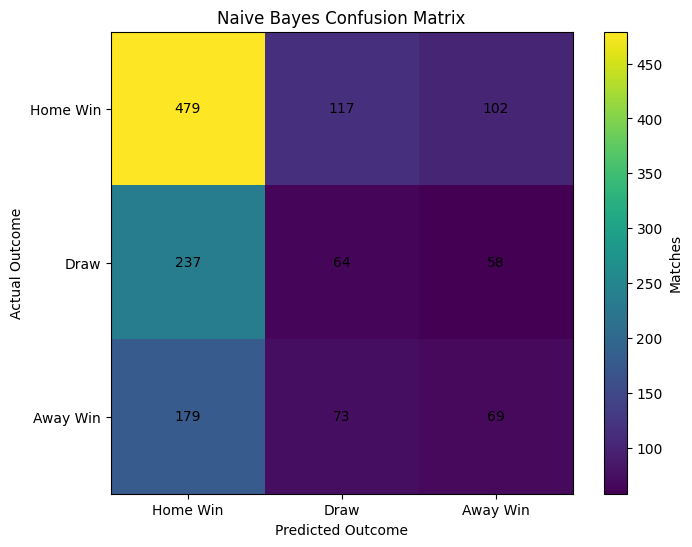

In [195]:
#Display Naive Bayes confusion matrix
nb_cm = confusion_matrix(y_test_nb, y_pred_nb, labels=["Home Win", "Draw", "Away Win"])
plt.figure(figsize=(8, 6))
plt.imshow(nb_cm)
plt.colorbar(label="Matches")
plt.xticks(range(3), ["Home Win", "Draw", "Away Win"])
plt.yticks(range(3), ["Home Win", "Draw", "Away Win"])
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.title("Naive Bayes Confusion Matrix")
for i in range(3):
    for j in range(3):
        plt.text(j, i, nb_cm[i, j], ha="center", va="center")
plt.show()


DIANA clusters: 4
Cluster sizes: [257, 52, 40, 1]
Silhouette Score: 0.2526


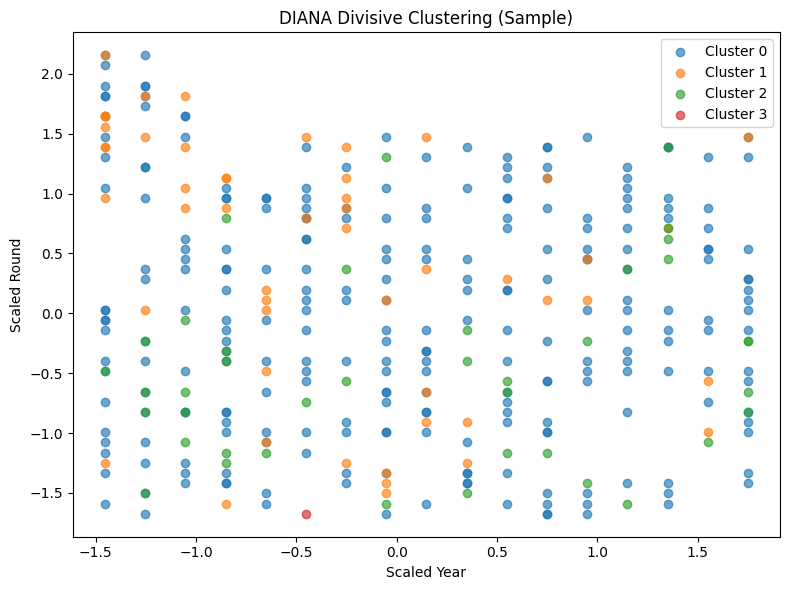

In [196]:
diana_data = df_clean[["Ano", "Rodada", "Gols_mandante", "Gols_visitante", "Total_Goals"]].dropna().copy()
diana_sample = diana_data.sample(n=min(350, len(diana_data)), random_state=42)
diana_scaled = StandardScaler().fit_transform(diana_sample)

#DIANA 
def diana(X, max_clusters=4):
    from scipy.spatial.distance import cdist
    clusters = [list(range(len(X)))]
    while len(clusters) < max_clusters:
        diameters = []
        for cluster in clusters:
            if len(cluster) < 2:
                diameters.append(0)
            else:
                distances = cdist(X[cluster], X[cluster])
                diameters.append(distances.max())
        split_index = int(np.argmax(diameters))
        cluster = clusters.pop(split_index)
        if len(cluster) < 2:
            clusters.append(cluster)
            break

        cluster_values = X[cluster]
        cluster_mean = cluster_values.mean(axis=0)
        distance_from_mean = np.linalg.norm(cluster_values - cluster_mean, axis=1)
        seed_pos = int(np.argmax(distance_from_mean))
        splinter = [cluster[seed_pos]]
        remaining = cluster.copy()
        remaining.remove(cluster[seed_pos])

        changed = True
        while changed and remaining:
            changed = False
            main_mean = X[remaining].mean(axis=0)
            splinter_mean = X[splinter].mean(axis=0)
            moves = []
            for index in remaining:
                if np.linalg.norm(X[index] - splinter_mean) < np.linalg.norm(X[index] - main_mean):
                    moves.append(index)
            if moves:
                splinter.extend(moves)
                remaining = [index for index in remaining if index not in moves]
                changed = True
        if not remaining or not splinter:
            clusters.append(cluster)
            break
        clusters.extend([remaining, splinter])
    return clusters

diana_clusters = diana(diana_scaled, max_clusters=4)
diana_labels = np.zeros(len(diana_sample), dtype=int)
for cluster_id, cluster_indices in enumerate(diana_clusters):
    diana_labels[cluster_indices] = cluster_id

print("DIANA clusters:", len(diana_clusters))
print("Cluster sizes:", [len(cluster) for cluster in diana_clusters])
if len(set(diana_labels)) > 1:
    print("Silhouette Score:", round(silhouette_score(diana_scaled, diana_labels), 4))


plt.figure(figsize=(8, 6))
for cluster_id in np.unique(diana_labels):
    cluster_points = diana_scaled[diana_labels == cluster_id]
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1], label=f"Cluster {cluster_id}", alpha=0.65)
plt.xlabel("Scaled Year")
plt.ylabel("Scaled Round")
plt.title("DIANA Divisive Clustering (Sample)")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
#Pyspark is used enhance the performance of the association rule mining algorithms (DIC and AClose) by leveraging distributed computing capabilities. It allows for processing large datasets in parallel across multiple nodes, which can significantly reduce execution time and improve scalability.
#PySpark imports and session setup
from pyspark.sql import SparkSession
from pyspark.ml import Pipeline as SparkPipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder as SparkOneHotEncoder, VectorAssembler, StandardScaler as SparkStandardScaler
from pyspark.ml.classification import NaiveBayes as SparkNaiveBayes
from pyspark.ml.clustering import KMeans as SparkKMeans
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, ClusteringEvaluator

spark = SparkSession.builder.appName("BrasileiraoEndsem").master("local[*]").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)


In [ ]:
#PySpark Naive Bayes compared with local Gaussian Naive Bayes
#Prepare class labels and categorical predictors for Spark ML
spark_nb_data = nb_data[["Ano", "Rodada", "Mandante_UF", "Visitante_UF", "Outcome"]].copy()
spark_nb_data["Outcome"] = spark_nb_data["Outcome"].astype(str)

#Train/test split already defined above; reuse the same row indices for local comparison
train_indices = X_train_nb.index
test_indices = X_test_nb.index
spark_train_pd = spark_nb_data.loc[train_indices].copy()
spark_test_pd = spark_nb_data.loc[test_indices].copy()

spark_train_nb = spark.createDataFrame(spark_train_pd)
spark_test_nb = spark.createDataFrame(spark_test_pd)

state_indexers = [
    StringIndexer(inputCol=col, outputCol=col + "_idx", handleInvalid="keep")
    for col in ["Mandante_UF", "Visitante_UF"]
]
state_encoders = [
    SparkOneHotEncoder(inputCol=col + "_idx", outputCol=col + "_vec")
    for col in ["Mandante_UF", "Visitante_UF"]
]
label_indexer = StringIndexer(inputCol="Outcome", outputCol="label", handleInvalid="keep")
feature_assembler = VectorAssembler(
    inputCols=["Ano", "Rodada", "Mandante_UF_vec", "Visitante_UF_vec"],
    outputCol="features"
)
spark_nb = SparkNaiveBayes(featuresCol="features", labelCol="label", modelType="multinomial")
spark_nb_pipeline = SparkPipeline(stages=state_indexers + state_encoders + [label_indexer, feature_assembler, spark_nb])

start_time = time.perf_counter()
spark_nb_model = spark_nb_pipeline.fit(spark_train_nb)
spark_nb_elapsed = time.perf_counter() - start_time
spark_nb_predictions = spark_nb_model.transform(spark_test_nb)

#Spark classification evaluation
nb_evaluator = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
spark_nb_accuracy = nb_evaluator.evaluate(spark_nb_predictions)
print("Spark Naive Bayes fit time:", round(spark_nb_elapsed, 3))
print("Spark Naive Bayes accuracy:", round(spark_nb_accuracy, 4))


In [ ]:
#Measure local Naive Bayes fit time on the same prepared split
start_time = time.perf_counter()
nb_timing_model = GaussianNB()
nb_timing_model.fit(X_train_nb, y_train_nb)
nb_local_fit_time = time.perf_counter() - start_time
nb_local_accuracy = accuracy_score(y_test_nb, nb_timing_model.predict(X_test_nb))

nb_performance = pd.DataFrame({
    "Implementation": ["Local (scikit-learn)", "PySpark"],
    "Fit Time (seconds)": [nb_local_fit_time, spark_nb_elapsed],
    "Accuracy": [nb_local_accuracy, spark_nb_accuracy]
})
print(nb_performance)


In [ ]:
#K-Means performance comparison: scikit-learn vs PySpark
cluster_data = df_clean[["Ano", "Rodada", "Gols_mandante", "Gols_visitante", "Total_Goals"]].dropna().sample(
    n=min(2500, len(df_clean)), random_state=42
).copy()
cluster_scaler = StandardScaler()
cluster_values = cluster_scaler.fit_transform(cluster_data)

start_time = time.perf_counter()
local_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
local_kmeans_labels = local_kmeans.fit_predict(cluster_values)
local_kmeans_time = time.perf_counter() - start_time
local_kmeans_silhouette = silhouette_score(cluster_values, local_kmeans_labels)

#Create Spark DataFrame from scaled numeric features
spark_cluster_pd = pd.DataFrame(cluster_values, columns=["f" + str(i) for i in range(cluster_values.shape[1])])
spark_cluster_df = spark.createDataFrame(spark_cluster_pd)
assembler_spark = VectorAssembler(inputCols=spark_cluster_pd.columns.tolist(), outputCol="features")
spark_kmeans = SparkKMeans(k=3, seed=42, featuresCol="features", predictionCol="cluster")
spark_kmeans_pipeline = SparkPipeline(stages=[assembler_spark, spark_kmeans])

start_time = time.perf_counter()
spark_kmeans_model = spark_kmeans_pipeline.fit(spark_cluster_df)
spark_kmeans_time = time.perf_counter() - start_time
spark_cluster_predictions = spark_kmeans_model.transform(spark_cluster_df)

cluster_evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="cluster", metricName="silhouette", distanceMeasure="squaredEuclidean")
spark_kmeans_silhouette = cluster_evaluator.evaluate(spark_cluster_predictions)

cluster_performance = pd.DataFrame({
    "Implementation": ["Local (scikit-learn)", "PySpark"],
    "Fit Time (seconds)": [local_kmeans_time, spark_kmeans_time],
    "Silhouette Score": [local_kmeans_silhouette, spark_kmeans_silhouette]
})
print(cluster_performance)


In [ ]:
#Combined measured timings
performance_summary = pd.DataFrame({
    "Technique": ["Naive Bayes", "K-Means"],
    "Local Time (s)": [nb_local_fit_time, local_kmeans_time],
    "PySpark Time (s)": [spark_nb_elapsed, spark_kmeans_time]
})
performance_summary["Spark Speedup"] = performance_summary["Local Time (s)"] / performance_summary["PySpark Time (s)"].replace(0, np.nan)
print(performance_summary)

for _, row in performance_summary.iterrows():
    if row["Spark Speedup"] > 1:
        print(f"{row['Technique']}: Spark was {row['Spark Speedup']:.2f}x faster in this run.")
    else:
        print(f"{row['Technique']}: local execution was faster in this run; Spark overhead likely dominates at this dataset size.")
spark.stop()